In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# read in data
df = pd.read_parquet("/Users/ben/Projects/Instacart/data/final.parquet")
df

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33819101,3421063,14233,3,1,169679,train,30,0,10,4.0,Natural Artesian Water,115,7,water seltzer sparkling water,beverages
33819102,3421063,35548,4,1,169679,train,30,0,10,4.0,Twice Baked Potatoes,13,20,prepared meals,deli
33819103,3421070,35951,1,1,139822,train,15,6,10,8.0,Organic Unsweetened Almond Milk,91,16,soy lactosefree,dairy eggs
33819104,3421070,16953,2,1,139822,train,15,6,10,8.0,Creamy Peanut Butter,88,13,spreads,pantry


In [4]:
# create target variable
df["next_order_within_7_days"] = df["order_id"].map(
    pd.read_csv(
        "/Users/ben/Projects/Instacart/data/raw/orders.csv",
        usecols=["order_id", "user_id", "order_number", "days_since_prior_order"]
    )
    .sort_values(["user_id", "order_number"])
    .set_index("order_id")
    .groupby("user_id")["days_since_prior_order"]
    .shift(-1)
)

df["next_order_within_7_days"] = (
    df["next_order_within_7_days"]
    .le(7)
    .where(df["next_order_within_7_days"].notna())
    .astype("boolean")
)

df

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department,next_order_within_7_days
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs,False
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce,False
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry,False
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry,False
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33819101,3421063,14233,3,1,169679,train,30,0,10,4.0,Natural Artesian Water,115,7,water seltzer sparkling water,beverages,<NA>
33819102,3421063,35548,4,1,169679,train,30,0,10,4.0,Twice Baked Potatoes,13,20,prepared meals,deli,<NA>
33819103,3421070,35951,1,1,139822,train,15,6,10,8.0,Organic Unsweetened Almond Milk,91,16,soy lactosefree,dairy eggs,<NA>
33819104,3421070,16953,2,1,139822,train,15,6,10,8.0,Creamy Peanut Butter,88,13,spreads,pantry,<NA>


In [5]:
# split data into train, validation, and test sets
df["order_from_end"] = (
    df.groupby("user_id")["order_number"]
    .rank(method="dense", ascending=False)
    .astype(int) - 1
)

test_df = df[df["order_from_end"] == 0].drop(columns=["order_from_end"])
val_df = df[df["order_from_end"] == 1].drop(columns=["order_from_end"])
train_df = df[df["order_from_end"] >= 2].drop(columns=["order_from_end"])

train_df = train_df.dropna(subset=["next_order_within_7_days"])
val_df = val_df.dropna(subset=["next_order_within_7_days"])

In [6]:
train_df

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department,next_order_within_7_days
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs,False
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce,False
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry,False
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry,False
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32434484,3421083,39678,6,1,25247,prior,24,2,6,21.0,Free & Clear Natural Dishwasher Detergent,74,17,dish detergents,household,False
32434485,3421083,11352,7,0,25247,prior,24,2,6,21.0,Organic Mini Sandwich Crackers Peanut Butter,78,19,crackers,snacks,False
32434486,3421083,4600,8,0,25247,prior,24,2,6,21.0,All Natural French Toast Sticks,52,1,frozen breakfast,frozen,False
32434487,3421083,24852,9,1,25247,prior,24,2,6,21.0,Banana,24,4,fresh fruits,produce,False


## Feature Engineered Variables

In [7]:
# # Start generating feature vars
# train_df.groupby('order_id').agg(
#     product_count=('product_id', 'nunique'),  # unique products in order
#     reordered_count=('reordered', 'sum'),  # total products
#     reordered_rate = ('reordered', 'mean'),  # percentager of products reordered
#     aisle_count = ('aisle', 'nunique'),  # total aisles
#     department_count = ('department', 'nunique')  # total departments
#     )

In [8]:
# Create engineered features at the order leve - group by order
# Create features from department column values

order_df = train_df.groupby('order_id').agg(
    product_count=('product_id', 'nunique'),  # unique products in order
    reordered_count=('reordered', 'sum'),  # total reordered products
    reordered_rate=('reordered', 'mean'),  # percentager of products reordered; fraction from 0 to 1
    aisle_count = ('aisle', 'nunique'),  # total aisles
    department_count = ('department', 'nunique')  # total departments
)

dept_counts = pd.crosstab(
    train_df['order_id'],
    train_df['department']
).add_prefix('department_')

dept_pct = dept_counts.div(dept_counts.sum(axis=1), axis=0).mul(100)

order_df = order_df.join([
    dept_counts.gt(0).astype(int).add_suffix('_exists'),
    dept_counts.add_suffix('_count'),
    dept_pct.add_suffix('_pct')
])

order_df

,product_count,reordered_count,reordered_rate,aisle_count,department_count,department_alcohol_exists,department_babies_exists,department_bakery_exists,department_beverages_exists,department_breakfast_exists,...,department_household_pct,department_international_pct,department_meat seafood_pct,department_missing_pct,department_other_pct,department_pantry_pct,department_personal care_pct,department_pets_pct,department_produce_pct,department_snacks_pct
order_id,,,,,,,,,,,,,,,,,,,,,
2,9,6,0.666667,8,3,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.0,0.0,55.555556,0.000000,0.0,33.333333,0.000000
3,8,8,1.000000,6,4,0,0,1,0,0,...,0.000000,0.000000,12.500000,0.0,0.0,0.000000,0.000000,0.0,37.500000,0.000000
4,13,12,0.923077,9,5,0,0,1,1,1,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,7.692308,0.0,0.000000,30.769231
5,26,21,0.807692,19,11,0,0,0,1,0,...,11.538462,3.846154,3.846154,0.0,0.0,7.692308,3.846154,0.0,26.923077,15.384615
6,3,0,0.000000,3,2,0,0,0,1,0,...,66.666667,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3421079,1,0,0.000000,1,1,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,100.000000,0.0,0.000000,0.000000
3421080,9,4,0.444444,7,4,0,0,0,1,0,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,22.222222,0.000000
3421081,7,0,0.000000,7,7,0,0,1,1,0,...,0.000000,0.000000,0.000000,0.0,0.0,14.285714,0.000000,0.0,0.000000,14.285714


In [9]:
# Re-create the training set df at the order level by selecting appropriate
# summary statistic from product level data

train_order_df = train_df.groupby("order_id").agg(
    # product_count=("product_id", "nunique"),
    # reordered_count=("reordered", "sum"),
    # reordered_rate=("reordered", "mean"),
    # aisle_count=("aisle", "nunique"),
    # department_count=("department", "nunique"),
    user_id=("user_id", "first"),
    order_number=("order_number", "first"),
    order_dow=("order_dow", "first"),
    order_hour_of_day=("order_hour_of_day", "first"),
    days_since_prior_order=("days_since_prior_order", "first"),
    next_order_within_7_days=("next_order_within_7_days", "first"),
)

train_order_df

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,next_order_within_7_days
order_id,,,,,,
2,202279,3,5,9,8.0,False
3,205970,16,5,17,12.0,True
4,178520,36,1,9,7.0,True
5,156122,42,6,16,9.0,False
6,22352,4,1,12,30.0,False
...,...,...,...,...,...,...
3421079,108687,6,1,13,0.0,False
3421080,52726,2,1,11,2.0,False
3421081,117076,1,3,11,NaN,False


In [10]:
# Join training order level data to feature engineered variables from order level data

train_order_model_df = pd.merge(
    train_order_df,
    order_df,
    left_on="order_id",
    right_index=True,
    how="left",
    validate="one_to_one"
)

In [11]:
train_order_model_df

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,next_order_within_7_days,product_count,reordered_count,reordered_rate,aisle_count,...,department_household_pct,department_international_pct,department_meat seafood_pct,department_missing_pct,department_other_pct,department_pantry_pct,department_personal care_pct,department_pets_pct,department_produce_pct,department_snacks_pct
order_id,,,,,,,,,,,,,,,,,,,,,
2,202279,3,5,9,8.0,False,9,6,0.666667,8,...,0.000000,0.000000,0.000000,0.0,0.0,55.555556,0.000000,0.0,33.333333,0.000000
3,205970,16,5,17,12.0,True,8,8,1.000000,6,...,0.000000,0.000000,12.500000,0.0,0.0,0.000000,0.000000,0.0,37.500000,0.000000
4,178520,36,1,9,7.0,True,13,12,0.923077,9,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,7.692308,0.0,0.000000,30.769231
5,156122,42,6,16,9.0,False,26,21,0.807692,19,...,11.538462,3.846154,3.846154,0.0,0.0,7.692308,3.846154,0.0,26.923077,15.384615
6,22352,4,1,12,30.0,False,3,0,0.000000,3,...,66.666667,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3421079,108687,6,1,13,0.0,False,1,0,0.000000,1,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,100.000000,0.0,0.000000,0.000000
3421080,52726,2,1,11,2.0,False,9,4,0.444444,7,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,22.222222,0.000000
3421081,117076,1,3,11,NaN,False,7,0,0.000000,7,...,0.000000,0.000000,0.000000,0.0,0.0,14.285714,0.000000,0.0,0.000000,14.285714


#### Create features on order level data that wasn't done in previous steps (order number, day of week, hour of day)


In [12]:
# Let's take a look at Leoson's ideas.
# Should probably start another notebook but I probably shouldn't have called
# this one modeling.

# Am I now going to do modeling? Seems practical at this point.

In [13]:
# Establish a another baseline model for comparison. (Logistic Regression maybe?)
# For feature experimentation, you can try a few different groups: 
# Historical purchasing cadence only, Historical cadence + basket characteristics, 
# Historical cadence + basket characteristics + department indicators
# Explore some interesting business value questions: 
# e.g. Are predictions worse for new customers? 
# Does it struggle with customers who order irregularly? 
# Do the relationships involving baby products, alcohol, and dairy 
# remain useful after controlling for customer history?

# After these, adding some of these insights into the README file should create 
# quite a complete project that's ready to go.

In [14]:
# You already have days_since_prior_order and order_number; the other examples would require additional feature engineering.
# For example, someone who usually orders every five days might be likely to return within seven days regardless of what’s in their current basket.
# His suggested experiment is to start by asking: “How well can we predict their next order using just their ordering history?” 
# Then add basket characteristics and department features to see whether those provide additional predictive value.
# Any historical summary should use only information available at the order where you make the prediction, never future orders.

In [15]:
train_order_model_df

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,next_order_within_7_days,product_count,reordered_count,reordered_rate,aisle_count,...,department_household_pct,department_international_pct,department_meat seafood_pct,department_missing_pct,department_other_pct,department_pantry_pct,department_personal care_pct,department_pets_pct,department_produce_pct,department_snacks_pct
order_id,,,,,,,,,,,,,,,,,,,,,
2,202279,3,5,9,8.0,False,9,6,0.666667,8,...,0.000000,0.000000,0.000000,0.0,0.0,55.555556,0.000000,0.0,33.333333,0.000000
3,205970,16,5,17,12.0,True,8,8,1.000000,6,...,0.000000,0.000000,12.500000,0.0,0.0,0.000000,0.000000,0.0,37.500000,0.000000
4,178520,36,1,9,7.0,True,13,12,0.923077,9,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,7.692308,0.0,0.000000,30.769231
5,156122,42,6,16,9.0,False,26,21,0.807692,19,...,11.538462,3.846154,3.846154,0.0,0.0,7.692308,3.846154,0.0,26.923077,15.384615
6,22352,4,1,12,30.0,False,3,0,0.000000,3,...,66.666667,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3421079,108687,6,1,13,0.0,False,1,0,0.000000,1,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,100.000000,0.0,0.000000,0.000000
3421080,52726,2,1,11,2.0,False,9,4,0.444444,7,...,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,22.222222,0.000000
3421081,117076,1,3,11,NaN,False,7,0,0.000000,7,...,0.000000,0.000000,0.000000,0.0,0.0,14.285714,0.000000,0.0,0.000000,14.285714


In [38]:
# Create baseline model
# How well can we predict their next order using just their ordering history?

# use median baseline prediction
median_baseline = train_order_model_df.groupby('user_id')['days_since_prior_order'].median().reset_index().rename(
    columns={'days_since_prior_order':'median_baseline_pred'}
)

median_baseline

,user_id,median_baseline_pred
0,1,19.5
1,2,11.5
2,3,9.0
3,4,20.0
4,5,10.5
...,...,...
206204,206205,30.0
206205,206206,3.0
206206,206207,8.0
206207,206208,7.0


In [41]:
# Create function to move product df into order df (condense).

def create_order_df(product_df):
    return product_df.groupby("order_id").agg(
        user_id=("user_id", "first"),
        order_number=("order_number", "first"),
        order_dow=("order_dow", "first"),
        order_hour_of_day=("order_hour_of_day", "first"),
        days_since_prior_order=("days_since_prior_order", "first"),
        next_order_within_7_days=("next_order_within_7_days", "first"),
    )

In [44]:
val_order_df = create_order_df(val_df)
val_order_df

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,next_order_within_7_days
order_id,,,,,,
16,174840,18,3,12,13.0,False
25,59897,19,6,10,25.0,True
40,382,29,1,15,23.0,False
43,39630,14,5,17,4.0,True
54,91977,2,3,15,30.0,False
...,...,...,...,...,...,...
3421045,154825,6,6,11,30.0,False
3421051,123577,6,0,17,7.0,False
3421055,42599,10,6,20,30.0,False


In [45]:
# attach baseline prediction to validation set for comparison and scoring
val_order_df = val_order_df.merge(median_baseline, on="user_id", how="left")
val_order_df.head()

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,next_order_within_7_days,median_baseline_pred
0,174840,18,3,12,13.0,False,18.5
1,59897,19,6,10,25.0,True,16.0
2,382,29,1,15,23.0,False,7.0
3,39630,14,5,17,4.0,True,4.0
4,91977,2,3,15,30.0,False,NaN


In [46]:
val_order_df['binary_baseline_pred'] = val_order_df['median_baseline_pred'] <= 7.0
val_order_df

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,next_order_within_7_days,median_baseline_pred,binary_baseline_pred
0,174840,18,3,12,13.0,False,18.5,False
1,59897,19,6,10,25.0,True,16.0,False
2,382,29,1,15,23.0,False,7.0,True
3,39630,14,5,17,4.0,True,4.0,True
4,91977,2,3,15,30.0,False,NaN,False
...,...,...,...,...,...,...,...,...
206204,154825,6,6,11,30.0,False,23.0,False
206205,123577,6,0,17,7.0,False,7.5,False
206206,42599,10,6,20,30.0,False,24.0,False
206207,124485,3,1,14,30.0,False,24.0,False


In [47]:
# score
sum(val_order_df['binary_baseline_pred'] == val_order_df['next_order_within_7_days']) / len(val_order_df)

np.float64(0.7315151133073726)

In [49]:
# End

#### Old Exploratory analysis below - include some in report, not others

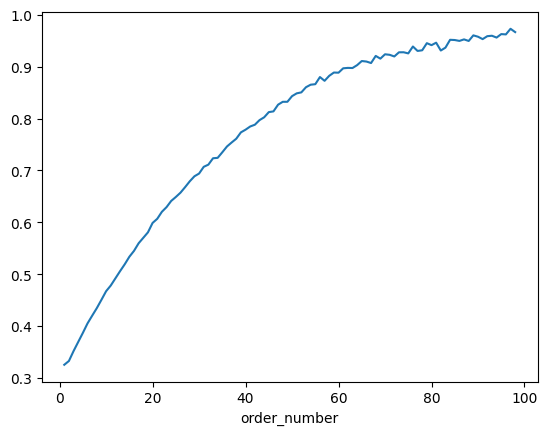

In [16]:
train_order_model_df.groupby("order_number")["next_order_within_7_days"].mean().astype(float).plot()
plt.show()

In [17]:
# day of week feature vars
train_order_model_df = train_order_model_df.join(
    pd.get_dummies(
        train_order_model_df["order_dow"] + 1,
        prefix="dow",
        dtype="int8"
    )
)

# peak day focused (be sure to cite orig person for this idea)
train_order_model_df["not_1"] = train_order_model_df["order_dow"].ne(0).astype("int8")
train_order_model_df["1_or_2"] = train_order_model_df["order_dow"].isin([0, 1]).astype("int8")
train_order_model_df["not_1_or_2"] = train_order_model_df["order_dow"].isin([2, 3, 4, 5, 6]).astype("int8")

# low med high
train_order_model_df["is_low"] = train_order_model_df["order_dow"].isin([3, 4]).astype("int8")
train_order_model_df["is_med"] = train_order_model_df["order_dow"].isin([2, 5, 6]).astype("int8")
train_order_model_df["is_high"] = train_order_model_df["order_dow"].isin([0, 1]).astype("int8")

train_order_model_df

,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,next_order_within_7_days,product_count,reordered_count,reordered_rate,aisle_count,...,dow_4,dow_5,dow_6,dow_7,not_1,1_or_2,not_1_or_2,is_low,is_med,is_high
order_id,,,,,,,,,,,,,,,,,,,,,
2,202279,3,5,9,8.0,False,9,6,0.666667,8,...,0,0,1,0,1,0,1,0,1,0
3,205970,16,5,17,12.0,True,8,8,1.000000,6,...,0,0,1,0,1,0,1,0,1,0
4,178520,36,1,9,7.0,True,13,12,0.923077,9,...,0,0,0,0,1,1,0,0,0,1
5,156122,42,6,16,9.0,False,26,21,0.807692,19,...,0,0,0,1,1,0,1,0,1,0
6,22352,4,1,12,30.0,False,3,0,0.000000,3,...,0,0,0,0,1,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3421079,108687,6,1,13,0.0,False,1,0,0.000000,1,...,0,0,0,0,1,1,0,0,0,1
3421080,52726,2,1,11,2.0,False,9,4,0.444444,7,...,0,0,0,0,1,1,0,0,0,1
3421081,117076,1,3,11,NaN,False,7,0,0.000000,7,...,1,0,0,0,1,0,1,1,0,0


In [18]:
# Create variables based on what we see in the graph
# peak times, down times
# that last hour of the day has the loweset hourly reorder rate and is interesting

train_order_model_df["morning_5_to_9"] = train_order_model_df["order_hour_of_day"].between(5, 9).astype("int8")
train_order_model_df["morning_5_to_10"] = train_order_model_df["order_hour_of_day"].between(5, 10).astype("int8")
train_order_model_df["morning_4_to_9"] = train_order_model_df["order_hour_of_day"].between(4, 9).astype("int8")
train_order_model_df["morning_4_to_10"] = train_order_model_df["order_hour_of_day"].between(4, 10).astype("int8")

train_order_model_df["evening_16_to_23"] = train_order_model_df["order_hour_of_day"].between(16, 23).astype("int8")
train_order_model_df["late_22_to_23"] = train_order_model_df["order_hour_of_day"].between(22, 23).astype("int8")
train_order_model_df["hour_23"] = train_order_model_df["order_hour_of_day"].eq(23).astype("int8")

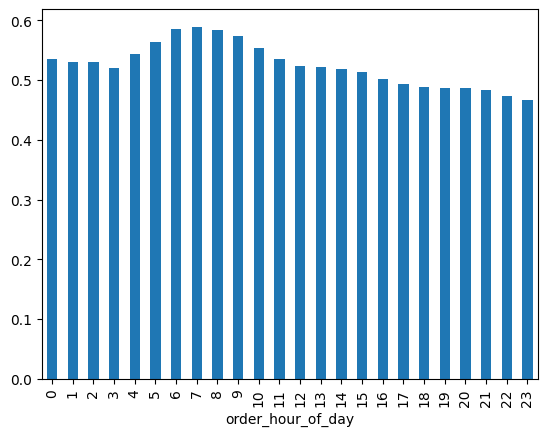

In [19]:
train_order_model_df.groupby("order_hour_of_day")["next_order_within_7_days"].mean().astype(float).plot.bar()
plt.show()

#### There is a whole bunch of stuff under here, a lot of which I don't remember doing. Go team.

## Notes on Feature Engineering

In [20]:
# General things to keep in mind

# Might want to know frequency of unique orders.
# And how that relates to size

# I don't recall what I meant by this. Unique orders will be rare - product-wise.

In [21]:
# Product ID

# 49,641 products. Could look at a select few. But looking at every product is beyond the scope of this current sprint.
# There could be some kind of 'key' product or products - something that spoils quickly, or something that
# Someone just really needs a lot (think inelastic demand goods, and/or 'sin' products)

# Product vs time of day. Drunk food and alcohol - ordered late night? 
# What other products might be related to time of day order?

# Would also want to combine into product groups by key word like 'baby'

# Could also try having marketing categories - i.e. 'low fat', 'reduced fat'. use AI repl

In [22]:
# Add to Cart Order - 
# size of order could be an important factor; this is just number of rows per order


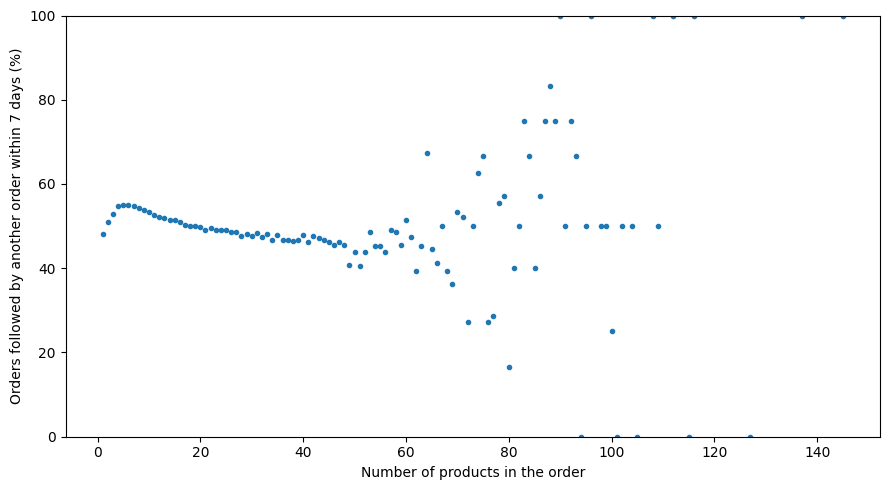

In [23]:
order_summary = train_df.groupby('order_id').agg(
    product_count=('product_id', 'nunique'),
    next_order_within_7_days=('next_order_within_7_days', 'first')
)

size_pct = (
    order_summary.groupby('product_count')['next_order_within_7_days']
    .mean()
    .mul(100)
)

size_pct.plot(style='.', figsize=(9, 5))
plt.xlabel('Number of products in the order')
plt.ylabel('Orders followed by another order within 7 days (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [24]:
# Reordered

# percentages of products that were reordered
# total products that were reordered

# My thinking - if someone has a regular basket of goods (high percentage) - they are likely to re-order quickly.
# Even if someone has a smaller group of re-order products, if there over all order is big, but their total products reordered meet a threshold, maybe 10 or so, they might be more likely to reorder quickly.


In [25]:
# Order number

# Do users start to develop habits?
# Say, after the third or fourth order, after they're familiar with the system, does their behavior change?


# Is there a honeymoon period? How about a divorce period?



In [26]:
# Day of week - look at this. I know Sunday and Monday should group together - the big shopping days.
# Will probably do one for each individual day.
# Wednesday and Thursday are low days.
# Could have low (WTh), medium (TuFSa), and high (SuM)

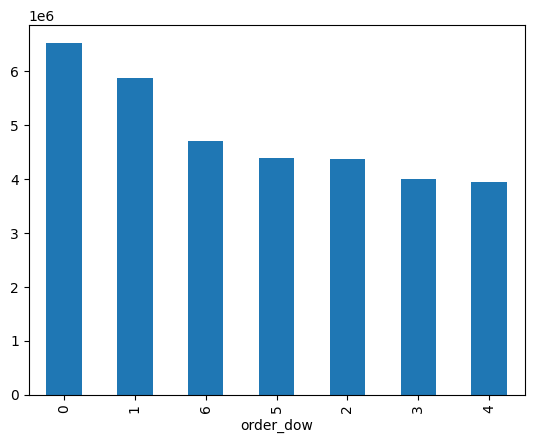

In [27]:
df['order_dow'].value_counts().plot(kind='bar')
plt.show()

In [28]:
# Hour of Day

# I would guess that late night orders are more desperate - a pizza, alcohol. They may be more one-offs, and less likely to re-order. Still, you could send them coupons for those certain items
# Might need a bool; is_late

In [29]:
# Days Since Prior Order

In [30]:
# Aisle

# 134 of these. Maybe just select a couple to start

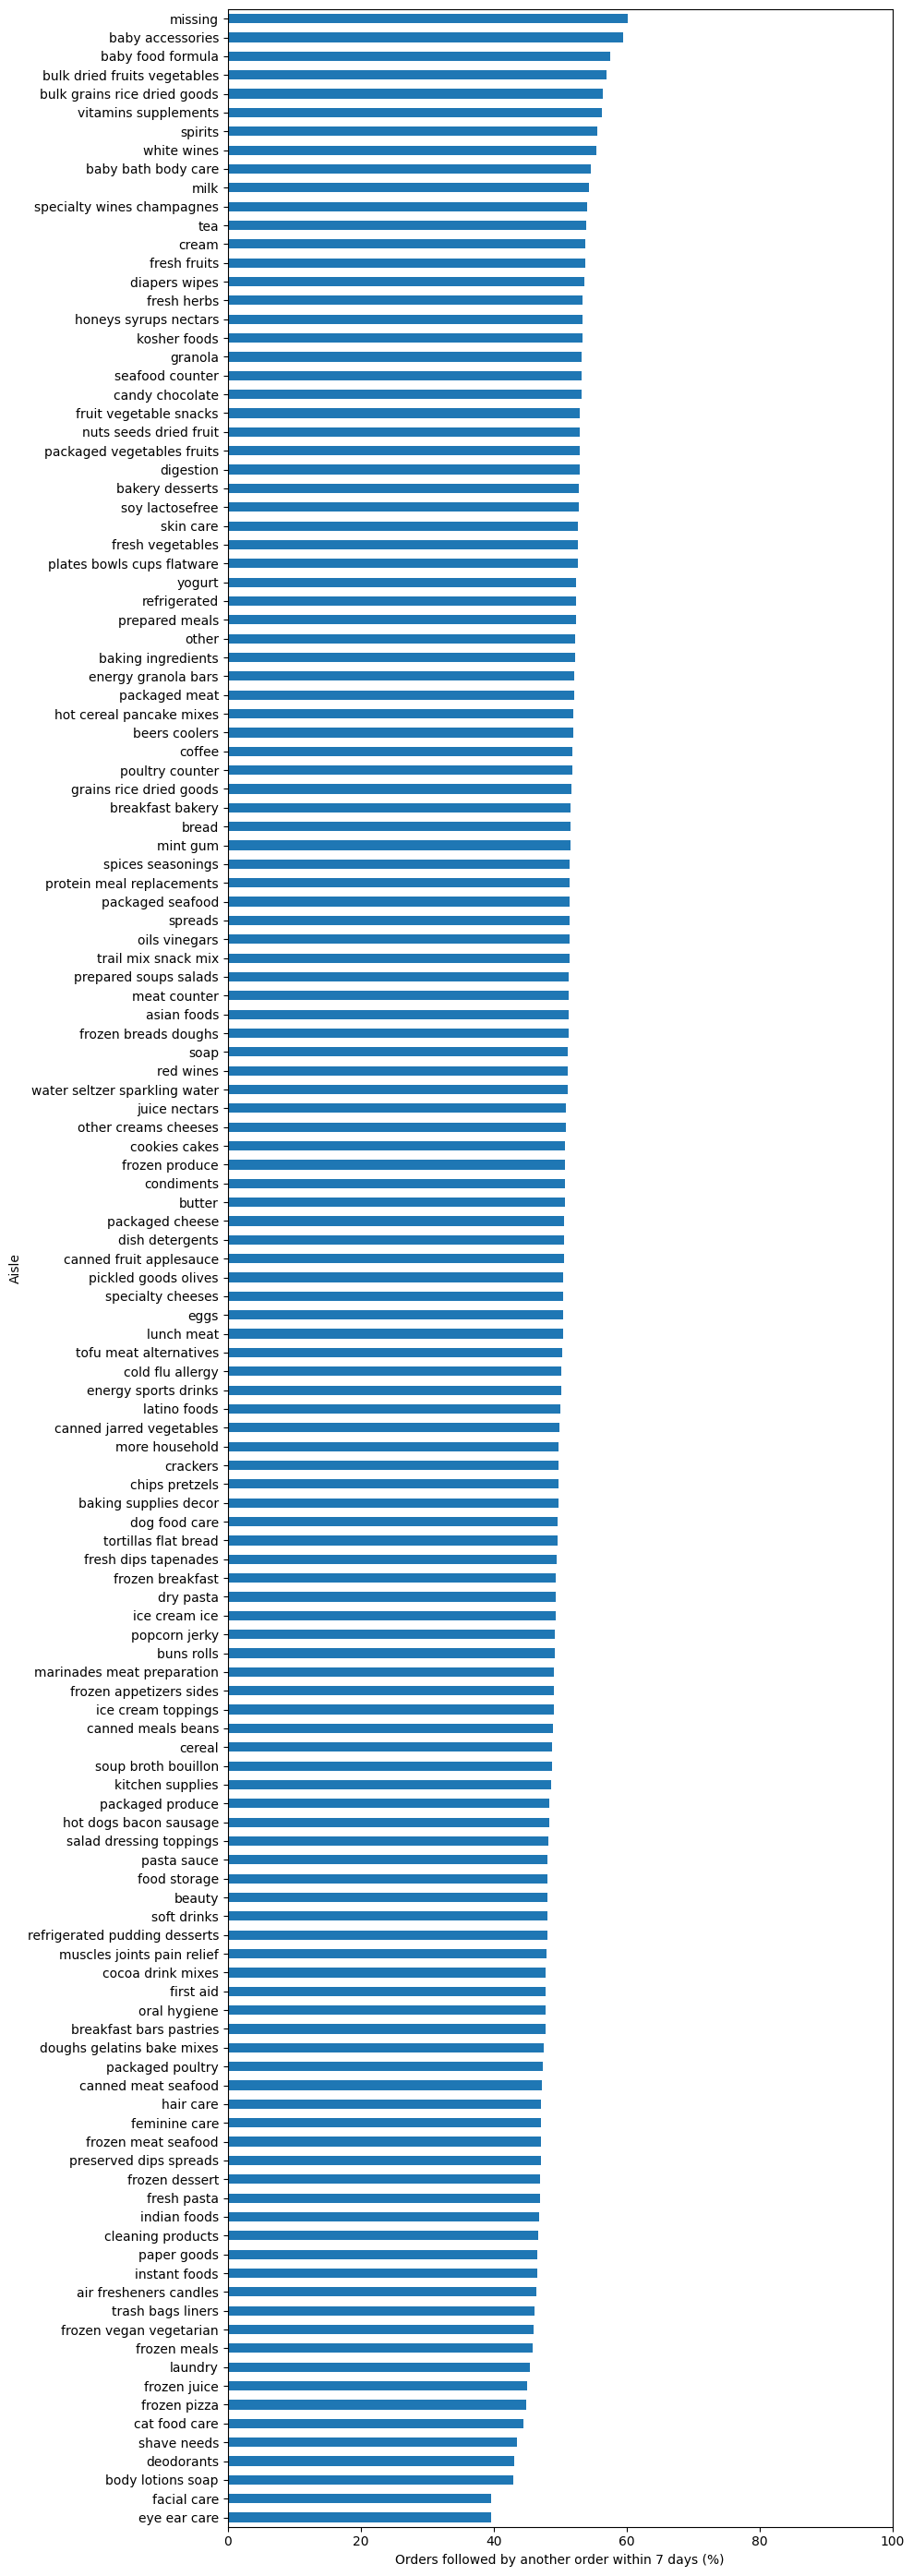

In [31]:
aisle_pct = (
    train_df[['order_id', 'aisle', 'next_order_within_7_days']]
    .drop_duplicates(['order_id', 'aisle'])
    .groupby('aisle')['next_order_within_7_days']
    .mean()
    .mul(100)
    .sort_values()
)

aisle_pct.plot.barh(figsize=(10, 28))
plt.xlabel('Orders followed by another order within 7 days (%)')
plt.ylabel('Aisle')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [32]:
with pd.option_context('display.max_rows', None):
    display(
        aisle_pct.sort_values(ascending=False).rename(
            'Orders followed by another order within 7 days (%)'
        ).round(2).reset_index()
    )

,aisle,Orders followed by another order within 7 days (%)
0,missing,60.17
1,baby accessories,59.45
2,baby food formula,57.49
3,bulk dried fruits vegetables,57.03
4,bulk grains rice dried goods,56.46
5,vitamins supplements,56.34
6,spirits,55.57
7,white wines,55.5
8,baby bath body care,54.61
9,milk,54.31


-- I hate this for new and young parents. Because I can see the rudimentary analysis. People with babies reorder a lot. Let's just inundate them with ads. And that's exactly what they do. As if there isn't enough on their plate and minds.

Now I'm wondering how much booze and baby orders are correlated.

In [33]:
# Department - create bools for each column

# Just 21 of these.
# My idea - bools for all 21. is this one hot encoder? is this still used?

In [34]:
from sklearn.preprocessing import OneHotEncoder

department_encoder = OneHotEncoder()
train_departments = department_encoder.fit_transform(train_df[['department']])

In [35]:
train_df = train_df.join(
    pd.DataFrame.sparse.from_spmatrix(
        train_departments,
        index=train_df.index,
        columns=department_encoder.get_feature_names_out()
    )
)

train_df

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,...,department_household,department_international,department_meat seafood,department_missing,department_other,department_pantry,department_personal care,department_pets,department_produce,department_snacks
0,2,33120,1,1,202279,prior,3,5,9,8.0,...,0,0,0,0,0,0,0,0,0,0
1,2,28985,2,1,202279,prior,3,5,9,8.0,...,0,0,0,0,0,0,0,0,1.0,0
2,2,9327,3,0,202279,prior,3,5,9,8.0,...,0,0,0,0,0,1.0,0,0,0,0
3,2,45918,4,1,202279,prior,3,5,9,8.0,...,0,0,0,0,0,1.0,0,0,0,0
4,2,30035,5,0,202279,prior,3,5,9,8.0,...,0,0,0,0,0,1.0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32434484,3421083,39678,6,1,25247,prior,24,2,6,21.0,...,1.0,0,0,0,0,0,0,0,0,0
32434485,3421083,11352,7,0,25247,prior,24,2,6,21.0,...,0,0,0,0,0,0,0,0,0,1.0
32434486,3421083,4600,8,0,25247,prior,24,2,6,21.0,...,0,0,0,0,0,0,0,0,0,0
32434487,3421083,24852,9,1,25247,prior,24,2,6,21.0,...,0,0,0,0,0,0,0,0,1.0,0


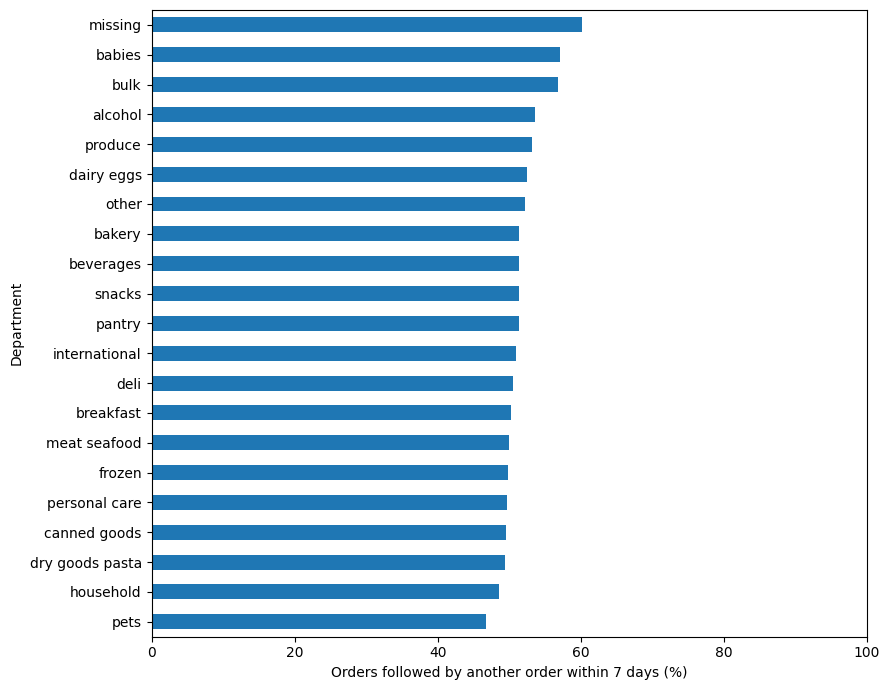

In [36]:
department_pct = (
    train_df[['order_id', 'department', 'next_order_within_7_days']]
    .drop_duplicates(['order_id', 'department'])
    .groupby('department')['next_order_within_7_days']
    .mean()
    .mul(100)
    .sort_values()
)

department_pct.plot.barh(figsize=(9, 7))
plt.xlabel('Orders followed by another order within 7 days (%)')
plt.ylabel('Department')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [37]:
department_pct.sort_values(ascending=False).rename(
    'Orders followed by another order within 7 days (%)'
).round(2).reset_index()

,department,Orders followed by another order within 7 days (%)
0,missing,60.17
1,babies,57.06
2,bulk,56.76
3,alcohol,53.6
4,produce,53.24
5,dairy eggs,52.51
6,other,52.27
7,bakery,51.41
8,beverages,51.41
9,snacks,51.41


-- Babies - saw that coming. Also booze. Bulk - I'm a bit surprised. Produce and dairy are also predictable. Dry, canned, froze near the bottom - also predictable. So, there is likely a predictive element in the deparment var.